# 02 — Scientometric Analysis of *Big Earth Data* (2017–2026): Manuscript Figures & Tables

This self-contained notebook reproduces **all figures (Figures 1–7 and Appendix Figures A1–A3), summary tables (Tables 1–3), and in-text statistics** reported in the quantitative scientometric analysis of *Big Earth Data*'s first decade (2017–2026).

* **Runs out-of-the-box:** Uses the pre-aggregated, anonymized datasets in `data/` and bundled Natural Earth 1:10m boundaries (`data/ne_10m_admin_0_countries.zip`) — no Scopus API key or network connection required.
* **Collection cutoff:** August 30, 2026 (`356` indexed items; `339` citable items = `276` Research Articles + `51` Notes + `12` Review Articles; `17` non-citable = `15` Editorials + `2` Errata).
* **Methodology:** Adapted from Juhász (2024, *IJGIS*), applying full-score country counting across all `339` citable publications.

## 1. Setup, Data Loading & Normalization Dictionaries

In [1]:
import math
import os
from collections import defaultdict
from pathlib import Path

import cartopy.crs as ccrs
import geopandas as gpd
import matplotlib
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import networkx as nx
import numpy as np
import pandas as pd

DATA_DIR = Path('data')
FIGURES_DIR = Path('figures')
TABLES_DIR = Path('tables')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# ── Load aggregated datasets ─────────────────────────────────────────────────
metrics = pd.read_csv(DATA_DIR / 'metrics_summary.csv').sort_values('year')
subtypes = pd.read_csv(DATA_DIR / 'SUBTYPE_YEAR.csv').sort_values('year')
countries = pd.read_csv(DATA_DIR / 'COUNTRIES.csv')
countries_year = pd.read_csv(DATA_DIR / 'COUNTRIES_YEAR.csv')
affiliations = pd.read_csv(DATA_DIR / 'AFFILIATIONS.csv')
collab = pd.read_csv(DATA_DIR / 'COLLAB.csv')
cities = pd.read_csv(DATA_DIR / 'CITIES.csv')
cities_geo = pd.read_csv(DATA_DIR / 'CITIES_GEOCODED.csv').dropna(subset=['lat', 'lon'])
ranking = pd.read_csv(DATA_DIR / 'ranking_scores.csv', index_col=0)
ranking.index = ranking.index.astype(int)

# ── Load bundled Natural Earth 1:10m country polygons (CC0 public domain) ────
world = gpd.read_file(f"zip://{DATA_DIR / 'ne_10m_admin_0_countries.zip'}")
world = world[world['NAME'] != 'Antarctica'].copy()

# ── Institution consolidation & English display names ────────────────────────
# Consolidates official CAS sub-institutes under Chinese Academy of Sciences
# while retaining UCAS and CBAS as distinct entities (see Methods §3.2).
CONSOLIDATIONS = {
    "Aerospace Information Research Institute": "Chinese Academy of Sciences",
    "Institute of Geographic Sciences and Natural Resources Research, Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Institute of Atmospheric Physics Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Northwest Institute of Eco-Environment and Resources": "Chinese Academy of Sciences",
    "Institute of Mountain Hazards and Environment, Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Xinjiang Institute of Ecology and Geography Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "CAS Center for Excellence & Innovation in Tibetan Plateau Earth System Sciences": "Chinese Academy of Sciences",
    "Research Center for Eco-Environmental Sciences Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Institute of Oceanology Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Northeast Institute of Geography and Agroecology": "Chinese Academy of Sciences",
    "Nanjing Institute of Geography and Limnology Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Institute of Applied Ecology, Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Institute of Geology and Geophysics Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Computer Network Information Center Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Institute of Chemistry Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Shanghai Astronomical Observatory Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "National Science Library, Chinese Academy of Sciences": "Chinese Academy of Sciences",
    "Innovation Academy for Precision Measurement Science and Technology,CAS": "Chinese Academy of Sciences",
    "National Space Science Center": "Chinese Academy of Sciences",
    "South China Sea Institute of Oceanology": "Chinese Academy of Sciences",
    "Wuhan Botanical Garden": "Chinese Academy of Sciences",
    "Department of Geoscience & Remote Sensing, TU Delft": "Delft University of Technology",
}

ENGLISH_NAMES = {
    "Universität Salzburg": "University of Salzburg",
    "Deutsches Zentrum für Luft- und Raumfahrt (DLR)": "German Aerospace Center (DLR)",
    "Helsingin Yliopisto": "University of Helsinki",
    "Université de Genève": "University of Geneva",
    "Consiglio Nazionale delle Ricerche": "National Research Council of Italy (CNR)",
    "Norges Teknisk-Naturvitenskapelige Universitet": "Norwegian Univ. of Science and Technology (NTNU)",
    "Universitat de València": "University of Valencia",
}


def normalise_institution(name: str) -> str:
    name = CONSOLIDATIONS.get(name, name)
    return ENGLISH_NAMES.get(name, name)


# ── Country -> Continent mapping (all 60 countries in corpus) ────────────────
CONTINENT = {
    'China': 'Asia', 'Japan': 'Asia', 'South Korea': 'Asia', 'India': 'Asia',
    'Iran': 'Asia', 'Turkey': 'Asia', 'Hong Kong S.A.R.': 'Asia',
    'Macao S.A.R': 'Asia', 'Singapore': 'Asia', 'Thailand': 'Asia',
    'Pakistan': 'Asia', 'Nepal': 'Asia', 'Sri Lanka': 'Asia',
    'Mongolia': 'Asia', 'Kazakhstan': 'Asia', 'Bangladesh': 'Asia',
    'Israel': 'Asia', 'Saudi Arabia': 'Asia', 'Jordan': 'Asia',
    'Vietnam': 'Asia', 'Taiwan': 'Asia', 'Malaysia': 'Asia', 'Indonesia': 'Asia',
    'Philippines': 'Asia', 'United Arab Emirates': 'Asia', 'Uzbekistan': 'Asia',
    'Myanmar': 'Asia', 'Cambodia': 'Asia', 'Laos': 'Asia',
    'United States of America': 'North America', 'Canada': 'North America',
    'Mexico': 'North America', 'Cuba': 'North America',
    'Brazil': 'South America', 'Colombia': 'South America',
    'Argentina': 'South America', 'Uruguay': 'South America',
    'Bolivia': 'South America', 'Chile': 'South America', 'Peru': 'South America',
    'Germany': 'Europe', 'United Kingdom': 'Europe', 'France': 'Europe',
    'Italy': 'Europe', 'Spain': 'Europe', 'Netherlands': 'Europe',
    'Switzerland': 'Europe', 'Austria': 'Europe', 'Sweden': 'Europe',
    'Denmark': 'Europe', 'Finland': 'Europe', 'Norway': 'Europe',
    'Belgium': 'Europe', 'Greece': 'Europe', 'Portugal': 'Europe',
    'Ireland': 'Europe', 'Poland': 'Europe', 'Czechia': 'Europe',
    'Romania': 'Europe', 'Estonia': 'Europe', 'Latvia': 'Europe',
    'Russia': 'Europe', 'Cyprus': 'Europe', 'Luxembourg': 'Europe',
    'Slovenia': 'Europe', 'Croatia': 'Europe', 'Hungary': 'Europe',
    'Republic of Serbia': 'Europe', 'Serbia': 'Europe', 'Ukraine': 'Europe',
    'Slovakia': 'Europe', 'Moldova': 'Europe',
    'Australia': 'Oceania', 'New Zealand': 'Oceania',
    'South Africa': 'Africa', 'Kenya': 'Africa', 'Nigeria': 'Africa',
    'Ethiopia': 'Africa', 'Morocco': 'Africa', 'Egypt': 'Africa',
    'Ghana': 'Africa', 'United Republic of Tanzania': 'Africa', 'Tanzania': 'Africa',
    'Mozambique': 'Africa', 'Zimbabwe': 'Africa', 'Uganda': 'Africa',
    'Rwanda': 'Africa', 'Senegal': 'Africa', 'Tunisia': 'Africa', 'Cameroon': 'Africa',
}

print(f"Total indexed items : {int(metrics['total_items'].sum())}")
print(f"Citable items       : {int(metrics['citable'].sum())} "
      f"(Articles={int(metrics['articles'].sum())}, Notes={int(metrics['notes'].sum())}, Reviews={int(metrics['reviews'].sum())})")
print(f"Non-citable items   : {int(metrics['non_citable'].sum())}")
print(f"Countries           : {len(countries)} | Cities: {len(cities)} ({len(cities_geo)} geocoded)")
print(f"Collab country pairs: {len(collab)} | Basemap polygons: {len(world)}")

Total indexed items : 356
Citable items       : 339 (Articles=276, Notes=51, Reviews=12)
Non-citable items   : 17
Countries           : 60 | Cities: 352 (348 geocoded)
Collab country pairs: 285 | Basemap polygons: 257


## 2. Summary Table 1 — Annual Publication & Collaboration Metrics

In [2]:
t1 = metrics[[
    'year', 'total_items', 'citable', 'articles', 'reviews', 'notes',
    'non_citable', 'multi_country', 'collab_rate'
]].copy()
t1.columns = [
    'Year', 'Total', 'Citable', 'Articles', 'Reviews', 'Notes',
    'Non-citable', 'Intl. items', 'Collab. rate (%)'
]
t1['Collab. rate (%)'] = t1['Collab. rate (%)'].round(1)

overall_collab_pct = metrics['multi_country'].sum() / metrics['citable'].sum() * 100

# Write Markdown
md_lines = [
    '| ' + ' | '.join(t1.columns) + ' |',
    '|' + '|'.join(['---:'] * len(t1.columns)) + '|',
]
for _, r in t1.iterrows():
    vals = [str(int(v)) if i < 8 else f"{v:.1f}" for i, v in enumerate(r)]
    md_lines.append('| ' + ' | '.join(vals) + ' |')
md_lines.append(
    f"| **Total** | **{int(metrics['total_items'].sum())}** | **{int(metrics['citable'].sum())}** | "
    f"**{int(metrics['articles'].sum())}** | **{int(metrics['reviews'].sum())}** | "
    f"**{int(metrics['notes'].sum())}** | **{int(metrics['non_citable'].sum())}** | "
    f"**{int(metrics['multi_country'].sum())}** | **{overall_collab_pct:.1f}** |"
)
(TABLES_DIR / 'table_1_metrics.md').write_text('\n'.join(md_lines) + '\n', encoding='utf-8')

# Write LaTeX
tex_lines = [
    '\\begin{tabular}{rrrrrrrrr}',
    '\\toprule',
    ' & '.join(c.replace('%', '\\%') for c in t1.columns) + ' \\\\',
    '\\midrule',
]
for _, r in t1.iterrows():
    vals = [str(int(v)) if i < 8 else f"{v:.1f}" for i, v in enumerate(r)]
    tex_lines.append(' & '.join(vals) + ' \\\\')
totals = [
    'Total', str(int(metrics['total_items'].sum())), str(int(metrics['citable'].sum())),
    str(int(metrics['articles'].sum())), str(int(metrics['reviews'].sum())),
    str(int(metrics['notes'].sum())), str(int(metrics['non_citable'].sum())),
    str(int(metrics['multi_country'].sum())), f"{overall_collab_pct:.1f}",
]
tex_lines += ['\\midrule', ' & '.join(totals) + ' \\\\', '\\bottomrule', '\\end{tabular}']
(TABLES_DIR / 'table_1_metrics.tex').write_text('\n'.join(tex_lines) + '\n', encoding='utf-8')

print(f"Saved -> {TABLES_DIR / 'table_1_metrics.md'} and .tex")
print('\n'.join(md_lines))

Saved -> tables/table_1_metrics.md and .tex
| Year | Total | Citable | Articles | Reviews | Notes | Non-citable | Intl. items | Collab. rate (%) |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 2017 | 12 | 11 | 11 | 0 | 0 | 1 | 4 | 36.4 |
| 2018 | 21 | 21 | 18 | 2 | 1 | 0 | 6 | 28.6 |
| 2019 | 22 | 21 | 18 | 0 | 3 | 1 | 7 | 33.3 |
| 2020 | 24 | 21 | 17 | 1 | 3 | 3 | 10 | 47.6 |
| 2021 | 28 | 25 | 23 | 0 | 2 | 3 | 8 | 32.0 |
| 2022 | 37 | 33 | 18 | 0 | 15 | 4 | 9 | 27.3 |
| 2023 | 41 | 38 | 29 | 1 | 8 | 3 | 19 | 50.0 |
| 2024 | 27 | 27 | 20 | 1 | 6 | 0 | 6 | 22.2 |
| 2025 | 60 | 58 | 52 | 2 | 4 | 2 | 20 | 34.5 |
| 2026 | 84 | 84 | 70 | 5 | 9 | 0 | 25 | 29.8 |
| **Total** | **356** | **339** | **276** | **12** | **51** | **17** | **114** | **33.6** |


## 3. Figure 1 — Annual Publication Volume by Document Type (2017–2026)

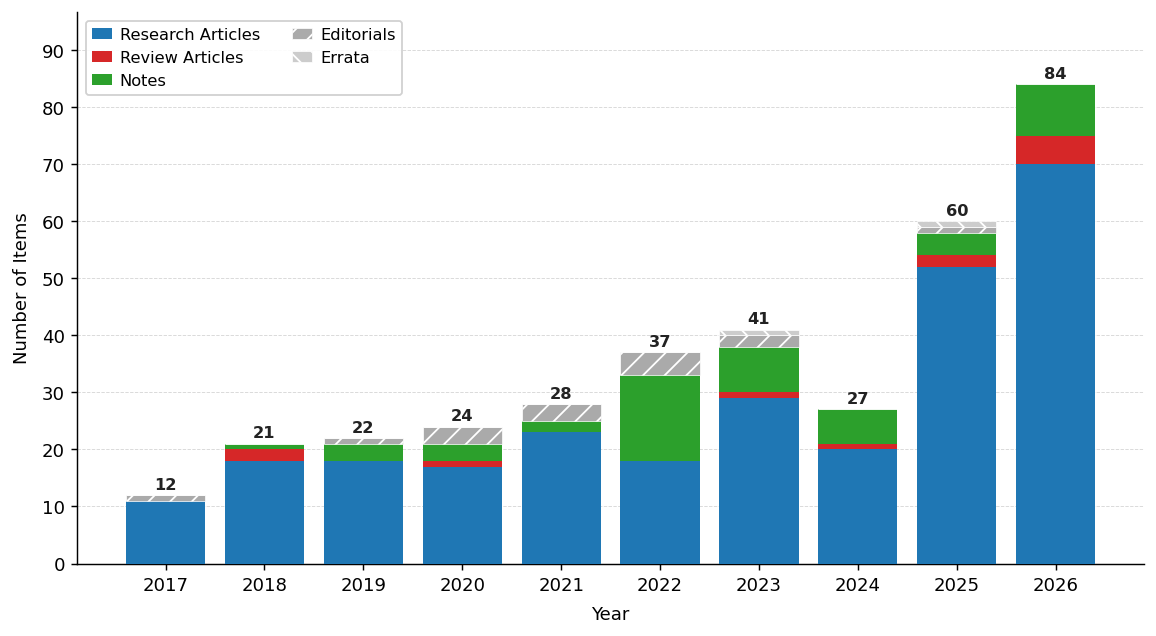

Saved -> figures/fig_01_volume.png


In [3]:
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})

COLORS_VOL = {
    'articles': '#1f77b4',
    'reviews': '#d62728',
    'notes': '#2ca02c',
    'editorials': '#aaaaaa',
    'errata': '#cccccc',
}

years_str = subtypes['year'].astype(str).tolist()
art_v = subtypes['Article'].values
rev_v = subtypes['Review'].values
not_v = subtypes['Data Paper'].values + subtypes['Note'].values
edi_v = subtypes['Editorial'].values
err_v = subtypes['Erratum'].values
tot_v = art_v + rev_v + not_v + edi_v + err_v

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(years_str))

ax.bar(x, art_v, color=COLORS_VOL['articles'], label='Research Articles', zorder=3)
ax.bar(x, rev_v, bottom=art_v, color=COLORS_VOL['reviews'], label='Review Articles', zorder=3)
ax.bar(x, not_v, bottom=art_v + rev_v, color=COLORS_VOL['notes'], label='Notes', zorder=3)
ax.bar(x, edi_v, bottom=art_v + rev_v + not_v, color=COLORS_VOL['editorials'],
       hatch='//', edgecolor='white', linewidth=0.4, label='Editorials', zorder=3)
ax.bar(x, err_v, bottom=art_v + rev_v + not_v + edi_v, color=COLORS_VOL['errata'],
       hatch='\\\\', edgecolor='white', linewidth=0.4, label='Errata', zorder=3)

for i, t in enumerate(tot_v):
    ax.text(i, int(t) + 0.5, str(int(t)), ha='center', va='bottom',
            fontsize=9, fontweight='bold', color='#222222')

ax.set_xticks(x)
ax.set_xticklabels(years_str)
ax.set_xlabel('Year', labelpad=6)
ax.set_ylabel('Number of Items', labelpad=6)
ax.set_ylim(0, tot_v.max() * 1.15)
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.5, zorder=0)
ax.legend(frameon=True, loc='upper left', fontsize=9, ncol=2,
          handlelength=1.2, handletextpad=0.5, framealpha=0.9, edgecolor='#cccccc')

fig.tight_layout()
out_f1 = FIGURES_DIR / 'fig_01_volume.png'
fig.savefig(out_f1, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print(f"Saved -> {out_f1}")

## 4. Figure 2 — Global Spatial Distribution of Contributing Countries (Robinson Projection)

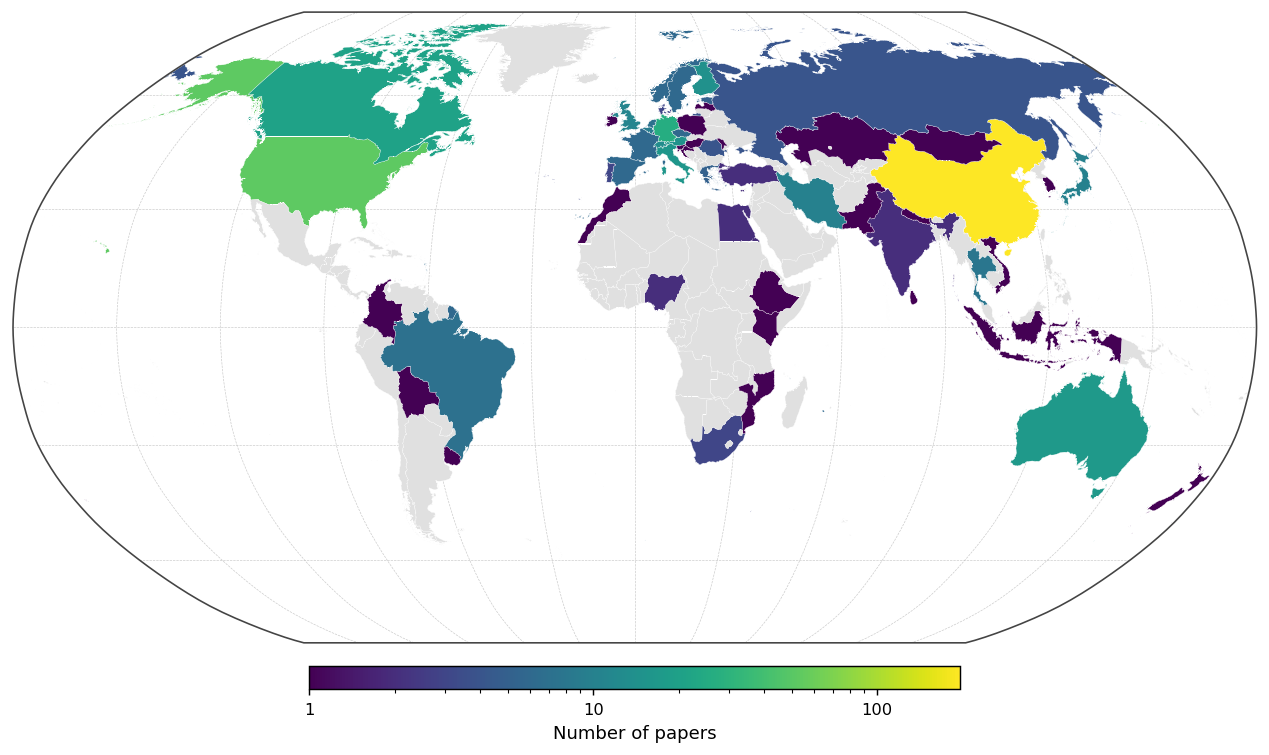

Saved -> figures/fig_02_choropleth.png (all 60 countries matched to Natural Earth 10m)


In [4]:
NE_NAME_MAP = {
    'Hong Kong S.A.R.': 'Hong Kong',
    'Macao S.A.R': 'Macao',
    'United States': 'United States of America',
    'United Republic of Tanzania': 'Tanzania',
    'Republic of Serbia': 'Serbia',
    'Czechia': 'Czechia',
    'Ivory Coast': 'Côte d\'Ivoire',
    'Democratic Republic of the Congo': 'Dem. Rep. Congo',
}

ne10_num = {}
for _, row in countries.iterrows():
    ne_name = NE_NAME_MAP.get(row['country'], row['country'])
    ne10_num[ne_name] = ne10_num.get(ne_name, 0) + int(row['num'])

world_map = world.copy()
world_map['num'] = world_map['NAME'].map(ne10_num).fillna(0).astype(int)

# Verify no country in COUNTRIES.csv failed to join to Natural Earth 10m
matched_ne = set(world_map.loc[world_map['num'] > 0, 'NAME'])
unmatched = set(ne10_num.keys()) - matched_ne
assert len(unmatched) == 0, f"Unmatched Natural Earth country names: {unmatched}"

vmax = max(ne10_num.values())
cmap_choro = plt.get_cmap('viridis')
norm_choro = mcolors.LogNorm(vmin=1, vmax=vmax)
world_map['color'] = world_map['num'].apply(lambda n: cmap_choro(norm_choro(n)) if n > 0 else '#e0e0e0')

proj = ccrs.Robinson()
fig = plt.figure(figsize=(12, 6), facecolor='white')
ax = fig.add_subplot(1, 1, 1, projection=proj, facecolor='white')
ax.set_global()

ax.gridlines(crs=ccrs.PlateCarree(),
             xlocs=range(-180, 181, 30), ylocs=range(-60, 61, 30),
             linewidth=0.35, color='#bbbbbb', linestyle='--', alpha=0.8)

for _, row in world_map.iterrows():
    ax.add_geometries([row.geometry], crs=ccrs.PlateCarree(),
                      facecolor=row['color'], edgecolor='white',
                      linewidth=0.15, zorder=2)

ax.spines['geo'].set_linewidth(0.9)
ax.spines['geo'].set_edgecolor('#444444')

sm = plt.cm.ScalarMappable(cmap=cmap_choro, norm=norm_choro)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', shrink=0.42, pad=0.03, aspect=28)
cbar.set_label('Number of papers', fontsize=10)
cbar.ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{int(v)}'))
cbar.ax.tick_params(labelsize=9)

plt.tight_layout(pad=0.3)
out_f2 = FIGURES_DIR / 'fig_02_choropleth.png'
fig.savefig(out_f2, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print(f"Saved -> {out_f2} (all {len(countries)} countries matched to Natural Earth 10m)")

## 5. Figure 3 & Table 2 — Top 15 Contributing Countries

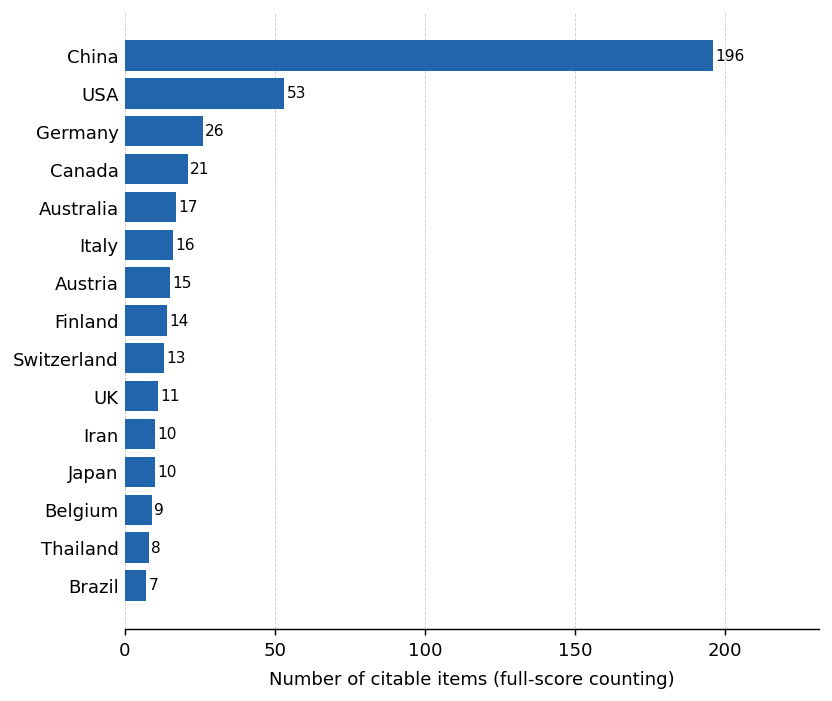

Saved -> figures/fig_03_top_countries.png
| Rank | Country | Items | Share |
|---:|:---|---:|---:|
| 1 | China | 196 | 57.8% |
| 2 | USA | 53 | 15.6% |
| 3 | Germany | 26 | 7.7% |
| 4 | Canada | 21 | 6.2% |
| 5 | Australia | 17 | 5.0% |
| 6 | Italy | 16 | 4.7% |
| 7 | Austria | 15 | 4.4% |
| 8 | Finland | 14 | 4.1% |
| 9 | Switzerland | 13 | 3.8% |
| 10 | UK | 11 | 3.2% |
| 11 | Iran | 10 | 2.9% |
| 12 | Japan | 10 | 2.9% |
| 13 | Belgium | 9 | 2.7% |
| 14 | Thailand | 8 | 2.4% |
| 15 | Brazil | 7 | 2.1% |


In [5]:
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
})

top_c = countries.sort_values(['num', 'country'], ascending=[False, True]).head(15).copy()
top_c['display_name'] = top_c['country'].replace({
    'United States of America': 'USA',
    'United Kingdom': 'UK',
    'Hong Kong S.A.R.': 'Hong Kong',
})
top_c_plot = top_c.iloc[::-1]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
bars = ax.barh(top_c_plot['display_name'], top_c_plot['num'], color='#2166ac', zorder=3)
for bar, val in zip(bars, top_c_plot['num']):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
            str(int(val)), va='center', fontsize=8.5)
ax.set_xlabel('Number of citable items (full-score counting)', labelpad=6)
ax.set_xlim(0, top_c_plot['num'].max() * 1.18)
ax.grid(axis='x', linestyle='--', linewidth=0.5, alpha=0.6, zorder=0)
ax.tick_params(axis='y', length=0)
fig.tight_layout()

out_f3 = FIGURES_DIR / 'fig_03_top_countries.png'
fig.savefig(out_f3, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
plt.rcParams['axes.spines.left'] = True
print(f"Saved -> {out_f3}")

# ── Table 2 ───────────────────────────────────────────────────────────────────
total_citable = int(metrics['citable'].sum())
t2 = top_c[['display_name', 'num']].reset_index(drop=True)
t2.index = range(1, 16)
t2['Share'] = (t2['num'] / total_citable * 100).round(1).map(lambda x: f"{x:.1f}%")
t2.columns = ['Country', 'Items', 'Share']

md_t2 = ['| Rank | Country | Items | Share |', '|---:|:---|---:|---:|']
for rk, r in t2.iterrows():
    md_t2.append(f"| {rk} | {r['Country']} | {int(r['Items'])} | {r['Share']} |")
(TABLES_DIR / 'table_2_countries.md').write_text('\n'.join(md_t2) + '\n', encoding='utf-8')

tex_t2 = ['\\begin{tabular}{rlrr}', '\\toprule', 'Rank & Country & Items & Share \\\\', '\\midrule']
for rk, r in t2.iterrows():
    tex_t2.append(f"{rk} & {r['Country']} & {int(r['Items'])} & {r['Share'].replace('%', '\\%')} \\\\")
tex_t2 += ['\\bottomrule', '\\end{tabular}']
(TABLES_DIR / 'table_2_countries.tex').write_text('\n'.join(tex_t2) + '\n', encoding='utf-8')
print('\n'.join(md_t2))

## 6. Figure 4 (Appendix) & Table 3 — Top 15 Contributing Institutions

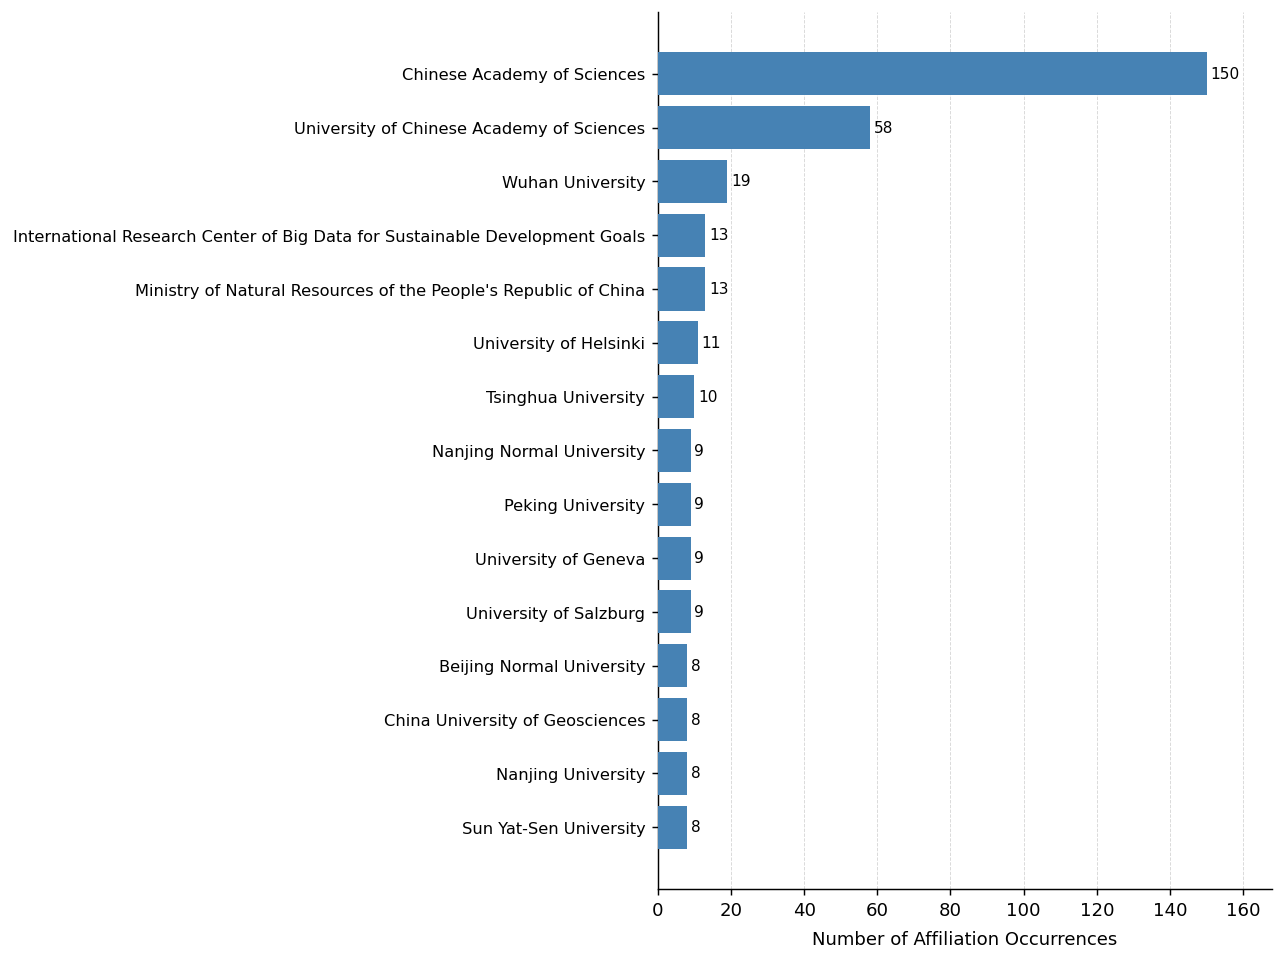

Saved -> figures/fig_04_top_institutions.png
| Rank | Institution | Affiliations |
|---:|:---|---:|
| 1 | Chinese Academy of Sciences | 150 |
| 2 | University of Chinese Academy of Sciences | 58 |
| 3 | Wuhan University | 19 |
| 4 | International Research Center of Big Data for Sustainable Development Goals | 13 |
| 5 | Ministry of Natural Resources of the People's Republic of China | 13 |
| 6 | University of Helsinki | 11 |
| 7 | Tsinghua University | 10 |
| 8 | Nanjing Normal University | 9 |
| 9 | Peking University | 9 |
| 10 | University of Geneva | 9 |
| 11 | University of Salzburg | 9 |
| 12 | Beijing Normal University | 8 |
| 13 | China University of Geosciences | 8 |
| 14 | Nanjing University | 8 |
| 15 | Sun Yat-Sen University | 8 |


In [6]:
aff_norm = affiliations.copy()
aff_norm['institution_norm'] = aff_norm['institution'].apply(normalise_institution)

inst_totals = (
    aff_norm.groupby('institution_norm', as_index=False)['num']
    .sum()
    .sort_values(['num', 'institution_norm'], ascending=[False, True])
)
top_inst = inst_totals.head(15).copy()
top_inst_plot = top_inst.iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 7.5))
bars = ax.barh(top_inst_plot['institution_norm'], top_inst_plot['num'], color='steelblue', zorder=3)
for bar, val in zip(bars, top_inst_plot['num']):
    ax.text(bar.get_width() + 1.0, bar.get_y() + bar.get_height() / 2,
            str(int(val)), va='center', fontsize=8.5)
ax.set_xlabel('Number of Affiliation Occurrences', labelpad=6)
ax.set_xlim(0, top_inst_plot['num'].max() * 1.12)
ax.tick_params(axis='y', labelsize=9)
ax.grid(axis='x', linestyle='--', linewidth=0.5, alpha=0.5, zorder=0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.tight_layout()

out_f4 = FIGURES_DIR / 'fig_04_top_institutions.png'
fig.savefig(out_f4, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print(f"Saved -> {out_f4}")

# ── Table 3 ───────────────────────────────────────────────────────────────────
t3 = top_inst.reset_index(drop=True)
t3.index = range(1, 16)
md_t3 = ['| Rank | Institution | Affiliations |', '|---:|:---|---:|']
for rk, r in t3.iterrows():
    md_t3.append(f"| {rk} | {r['institution_norm']} | {int(r['num'])} |")
(TABLES_DIR / 'table_3_institutions.md').write_text('\n'.join(md_t3) + '\n', encoding='utf-8')

tex_t3 = ['\\begin{tabular}{rlr}', '\\toprule', 'Rank & Institution & Affiliations \\\\', '\\midrule']
for rk, r in t3.iterrows():
    inst_tex = r['institution_norm'].replace('&', '\\&')
    tex_t3.append(f"{rk} & {inst_tex} & {int(r['num'])} \\\\")
tex_t3 += ['\\bottomrule', '\\end{tabular}']
(TABLES_DIR / 'table_3_institutions.tex').write_text('\n'.join(tex_t3) + '\n', encoding='utf-8')
print('\n'.join(md_t3))

## 7. Figure 5 — Annual International Collaboration Rate

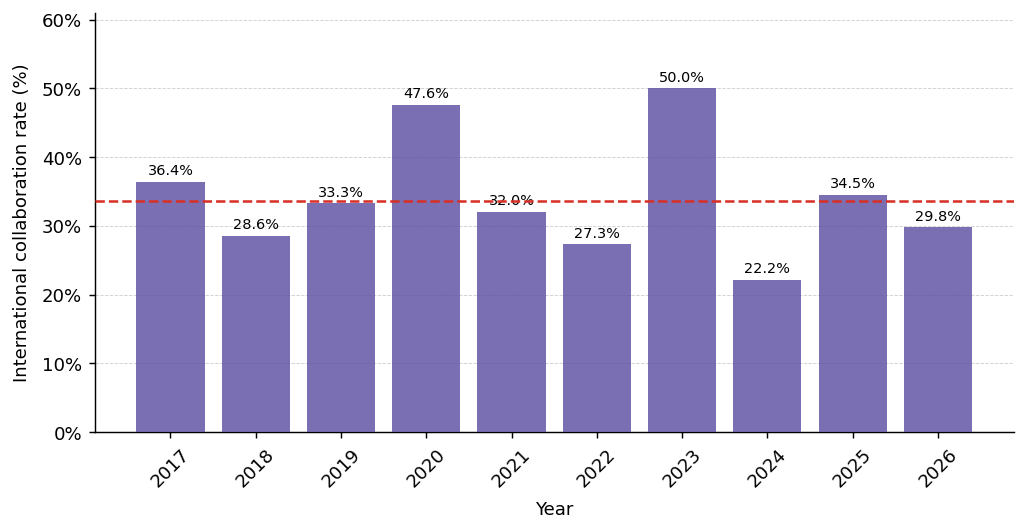

Saved -> figures/fig_05_collab_rate.png (overall collaboration rate = 33.6%)


In [7]:
years_col = metrics['year'].astype(str)
collab_pct = metrics['collab_rate']
overall_col = metrics['multi_country'].sum() / metrics['citable'].sum() * 100

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(years_col, collab_pct, color='#5e4fa2', alpha=0.82, zorder=3)

for bar, val in zip(bars, collab_pct):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.6,
            f'{val:.1f}%', ha='center', va='bottom', fontsize=8.0)

ax.axhline(overall_col, color='#d73027', linewidth=1.4, linestyle='--', zorder=4)

ax.set_xlabel('Year', labelpad=6)
ax.set_ylabel('International collaboration rate (%)', labelpad=6)
ax.set_ylim(0, collab_pct.max() * 1.22)
ax.yaxis.set_major_formatter(ticker.PercentFormatter())
ax.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.6, zorder=0)
ax.tick_params(axis='x', rotation=45)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()
out_f5 = FIGURES_DIR / 'fig_05_collab_rate.png'
fig.savefig(out_f5, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print(f"Saved -> {out_f5} (overall collaboration rate = {overall_col:.1f}%)")

## 8. Figure 6 — Continental Collaboration Network

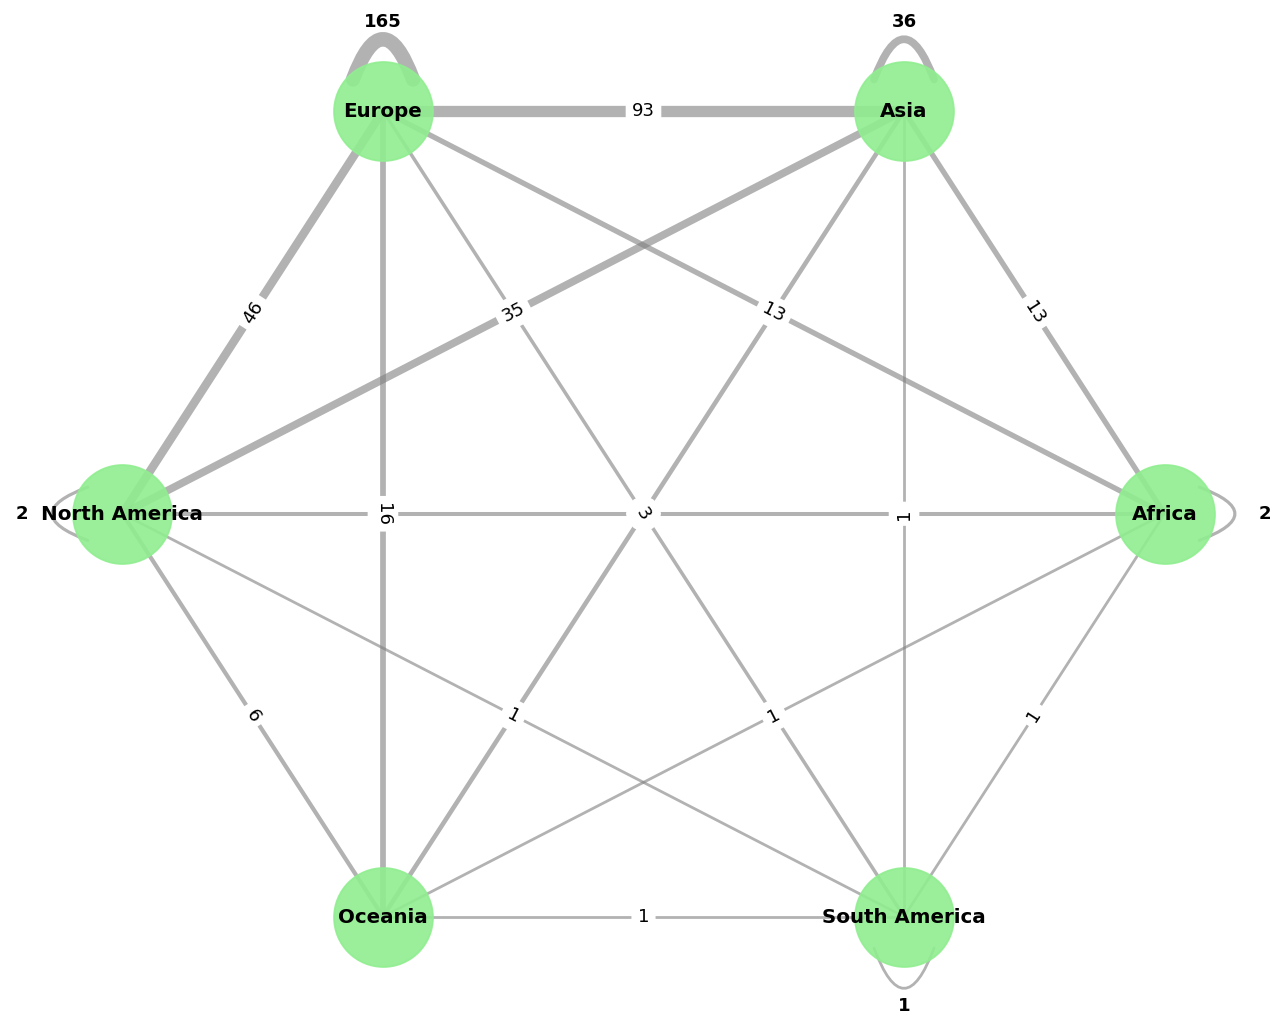

Saved -> figures/fig_06_continent_network.png


In [8]:
collab_cont = collab.copy()
collab_cont['cont_1'] = collab_cont['country_1'].map(CONTINENT)
collab_cont['cont_2'] = collab_cont['country_2'].map(CONTINENT)
assert collab_cont['cont_1'].isna().sum() == 0 and collab_cont['cont_2'].isna().sum() == 0, (
    "Unmapped country in CONTINENT dictionary!"
)

# Canonicalize pairs alphabetically so bidirectional links merge cleanly
collab_cont[['cont_1', 'cont_2']] = pd.DataFrame(
    [sorted([r.cont_1, r.cont_2]) for _, r in collab_cont.iterrows()],
    index=collab_cont.index,
)
cont_agg = collab_cont.groupby(['cont_1', 'cont_2'], as_index=False)['num'].sum()

self_loops = {}
cross_rows = []
for _, row in cont_agg.iterrows():
    if row['cont_1'] == row['cont_2']:
        self_loops[row['cont_1']] = int(row['num'])
    else:
        cross_rows.append(row)

G_cont = nx.Graph()
for c in sorted(set(cont_agg['cont_1']).union(cont_agg['cont_2'])):
    G_cont.add_node(c)
for row in cross_rows:
    G_cont.add_edge(row['cont_1'], row['cont_2'], weight=int(row['num']))

fig, ax = plt.subplots(figsize=(10, 8), facecolor='white')
ax.set_facecolor('white')
pos = nx.circular_layout(G_cont)

cross_edges = list(G_cont.edges(data=True))
all_weights = [d['weight'] for _, _, d in cross_edges] + list(self_loops.values())
max_w = max(all_weights) if all_weights else 1
cross_w = [1.0 + math.sqrt(d['weight'] / max_w) * 7 for _, _, d in cross_edges]

nx.draw_networkx_nodes(G_cont, pos, node_color='lightgreen', node_size=3000, alpha=0.9, ax=ax)
nx.draw_networkx_edges(G_cont, pos, width=cross_w, alpha=0.6, edge_color='gray', ax=ax)
nx.draw_networkx_labels(G_cont, pos, font_size=11, font_weight='bold', ax=ax)

edge_labels = {(u, v): d['weight'] for u, v, d in cross_edges}
nx.draw_networkx_edge_labels(G_cont, pos, edge_labels=edge_labels, font_size=10, ax=ax)

# Outward-pointing self-loops matching circular layout positions
LOOP_DIR = {
    'Europe': (0, 1),
    'Asia': (0, 1),
    'North America': (-1, 0),
    'Africa': (1, 0),
    'South America': (0, -1),
    'Oceania': (0, -1),
}

for cont, count in self_loops.items():
    if cont not in pos or count == 0:
        continue
    x_n, y_n = pos[cont]
    dx, dy = LOOP_DIR.get(cont, (0, 1))
    r_node = 0.045
    r_h = 0.06
    lift = r_node + 0.015
    if abs(dy) > abs(dx):
        posA = (x_n - r_h, y_n + dy * lift)
        posB = (x_n + r_h, y_n + dy * lift)
        rad = -1.4 * dy
        label_pos = (x_n, y_n + dy * (lift + r_h * 2.2))
    else:
        posA = (x_n + dx * lift, y_n - r_h)
        posB = (x_n + dx * lift, y_n + r_h)
        rad = 1.4 * dx
        label_pos = (x_n + dx * (lift + r_h * 2.2), y_n)

    lw = 1.0 + math.sqrt(count / max_w) * 7
    loop = mpatches.FancyArrowPatch(
        posA=posA, posB=posB,
        connectionstyle=f'arc3,rad={rad}',
        arrowstyle='-', linewidth=lw, color='gray', alpha=0.6, zorder=1,
    )
    ax.add_patch(loop)
    ax.text(*label_pos, str(count), ha='center', va='center',
            fontsize=10, color='black', fontfamily='sans-serif', fontweight='bold', zorder=5)

ax.axis('off')
plt.tight_layout()

out_f6 = FIGURES_DIR / 'fig_06_continent_network.png'
fig.savefig(out_f6, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print(f"Saved -> {out_f6}")

## 9. Figure 7 — Evolution of Journal-Level Impact Metrics (Main 2×2 Panel)

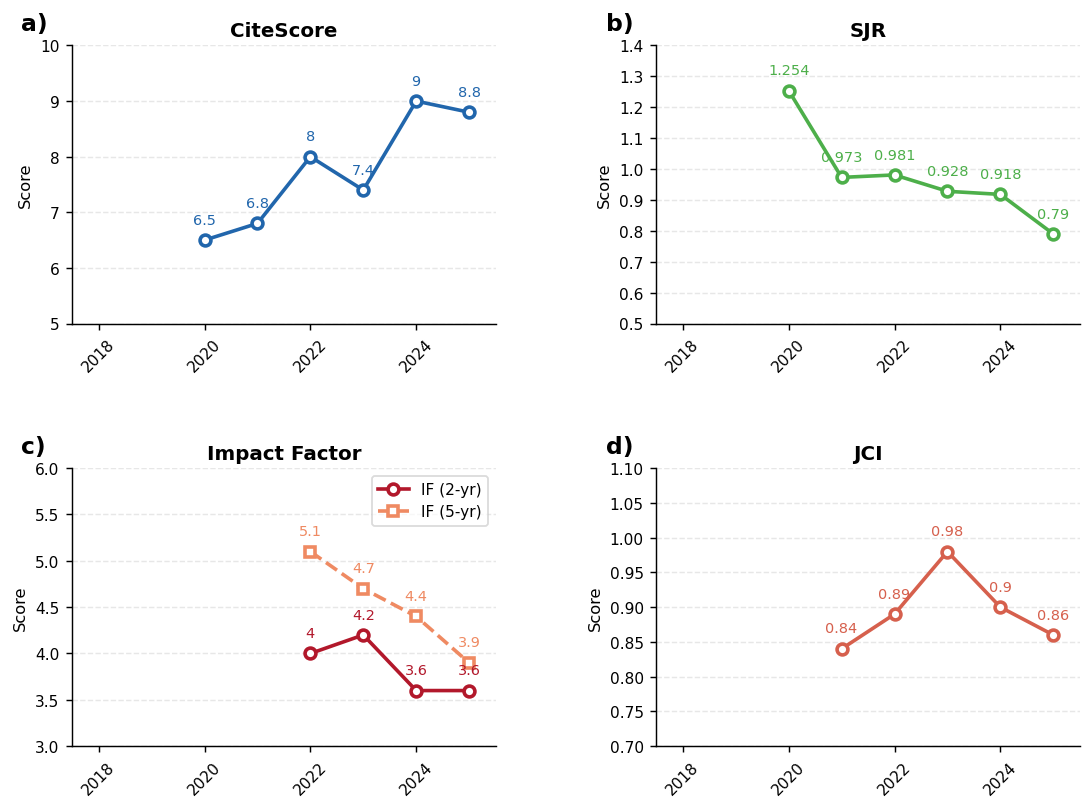

Saved -> figures/fig_07_journal_impact.png


In [9]:
YEARS_IMPACT = list(range(2018, 2026))
df_rk = ranking.reindex(YEARS_IMPACT)
XTICKS_IMPACT = [y for y in YEARS_IMPACT if y % 2 == 0]


def draw_metric_panel(ax, lbl, col, title, color, ls='-', marker='o',
                      ylim=None, round3sig=False,
                      col2=None, title2=None, color2=None, ls2='--', marker2='s'):
    s1 = df_rk[col].dropna()
    ax.plot(s1.index, s1.values, linestyle=ls, marker=marker, color=color,
            lw=2, ms=6, mfc='white', mew=2, label=title if col2 else None)
    for x_v, y_v in zip(s1.index, s1.values):
        fmt = f'{float(f"{y_v:.3g}"):g}' if round3sig else f'{y_v:g}'
        ax.annotate(fmt, (x_v, y_v), textcoords='offset points',
                    xytext=(0, 9), ha='center', fontsize=8, color=color)
    if col2:
        s2 = df_rk[col2].dropna()
        ax.plot(s2.index, s2.values, linestyle=ls2, marker=marker2, color=color2,
                lw=2, ms=6, mfc='white', mew=2, label=title2)
        for x_v, y_v in zip(s2.index, s2.values):
            ax.annotate(f'{y_v:g}', (x_v, y_v), textcoords='offset points',
                        xytext=(0, 9), ha='center', fontsize=8, color=color2)
        ax.legend(fontsize=8.5, framealpha=0.7, loc='upper right')
    ax.set_xlim(2017.5, 2025.5)
    ax.set_xticks(XTICKS_IMPACT)
    ax.tick_params(axis='x', labelsize=8.5, rotation=45)
    ax.tick_params(axis='y', labelsize=8.5)
    if ylim:
        ax.set_ylim(*ylim)
    ax.set_title(title if not col2 else 'Impact Factor', fontsize=11, fontweight='bold', pad=5)
    ax.set_ylabel('Score', fontsize=9)
    ax.grid(axis='y', alpha=0.3, ls='--')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.text(-0.12, 1.12, f'{lbl})', transform=ax.transAxes,
            fontsize=13, fontweight='bold', va='top')


fig, axes = plt.subplots(2, 2, figsize=(10, 7), facecolor='white')
fig.subplots_adjust(hspace=0.52, wspace=0.38)

draw_metric_panel(axes[0, 0], 'a', 'CiteScore', 'CiteScore', '#2166ac', ylim=(5, 10))
draw_metric_panel(axes[0, 1], 'b', 'SJR', 'SJR', '#4daf4a', ylim=(0.5, 1.4))
draw_metric_panel(axes[1, 0], 'c', 'IF', 'IF (2-yr)', '#b2182b', ylim=(3, 6),
                  col2='IF_5yr', title2='IF (5-yr)', color2='#ef8a62')
draw_metric_panel(axes[1, 1], 'd', 'JCI', 'JCI', '#d6604d', ylim=(0.7, 1.1))

out_f7 = FIGURES_DIR / 'fig_07_journal_impact.png'
fig.savefig(out_f7, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print(f"Saved -> {out_f7}")

## 10. Figure A1 (Appendix) — Supplementary Journal Impact Metrics

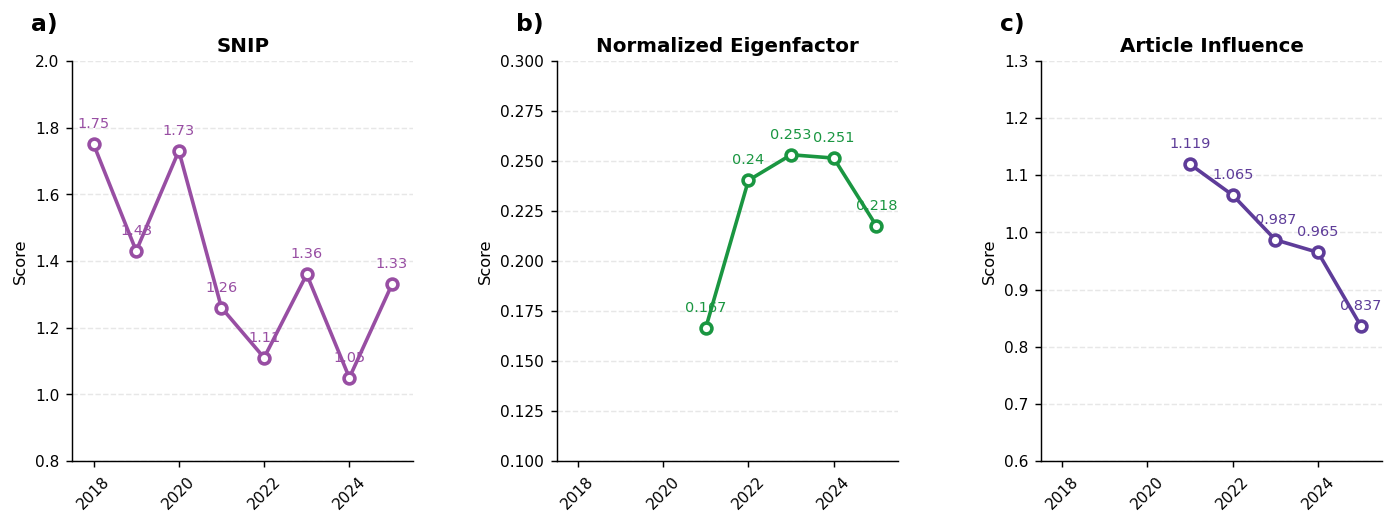

Saved -> figures/fig_A1_impact_appendix.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), facecolor='white')
fig.subplots_adjust(wspace=0.42)

draw_metric_panel(axes[0], 'a', 'SNIP', 'SNIP', '#984ea3', ylim=(0.8, 2.0))
draw_metric_panel(axes[1], 'b', 'Normalized_eigenfactor', 'Normalized Eigenfactor',
                  '#1a9641', ylim=(0.10, 0.30), round3sig=True)
draw_metric_panel(axes[2], 'c', 'Article_influence', 'Article Influence',
                  '#5e3c99', ylim=(0.6, 1.3))

out_fa1 = FIGURES_DIR / 'fig_A1_impact_appendix.png'
fig.savefig(out_fa1, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print(f"Saved -> {out_fa1}")

## 11. Figure A2 (Appendix) — Country-Level Collaboration Network

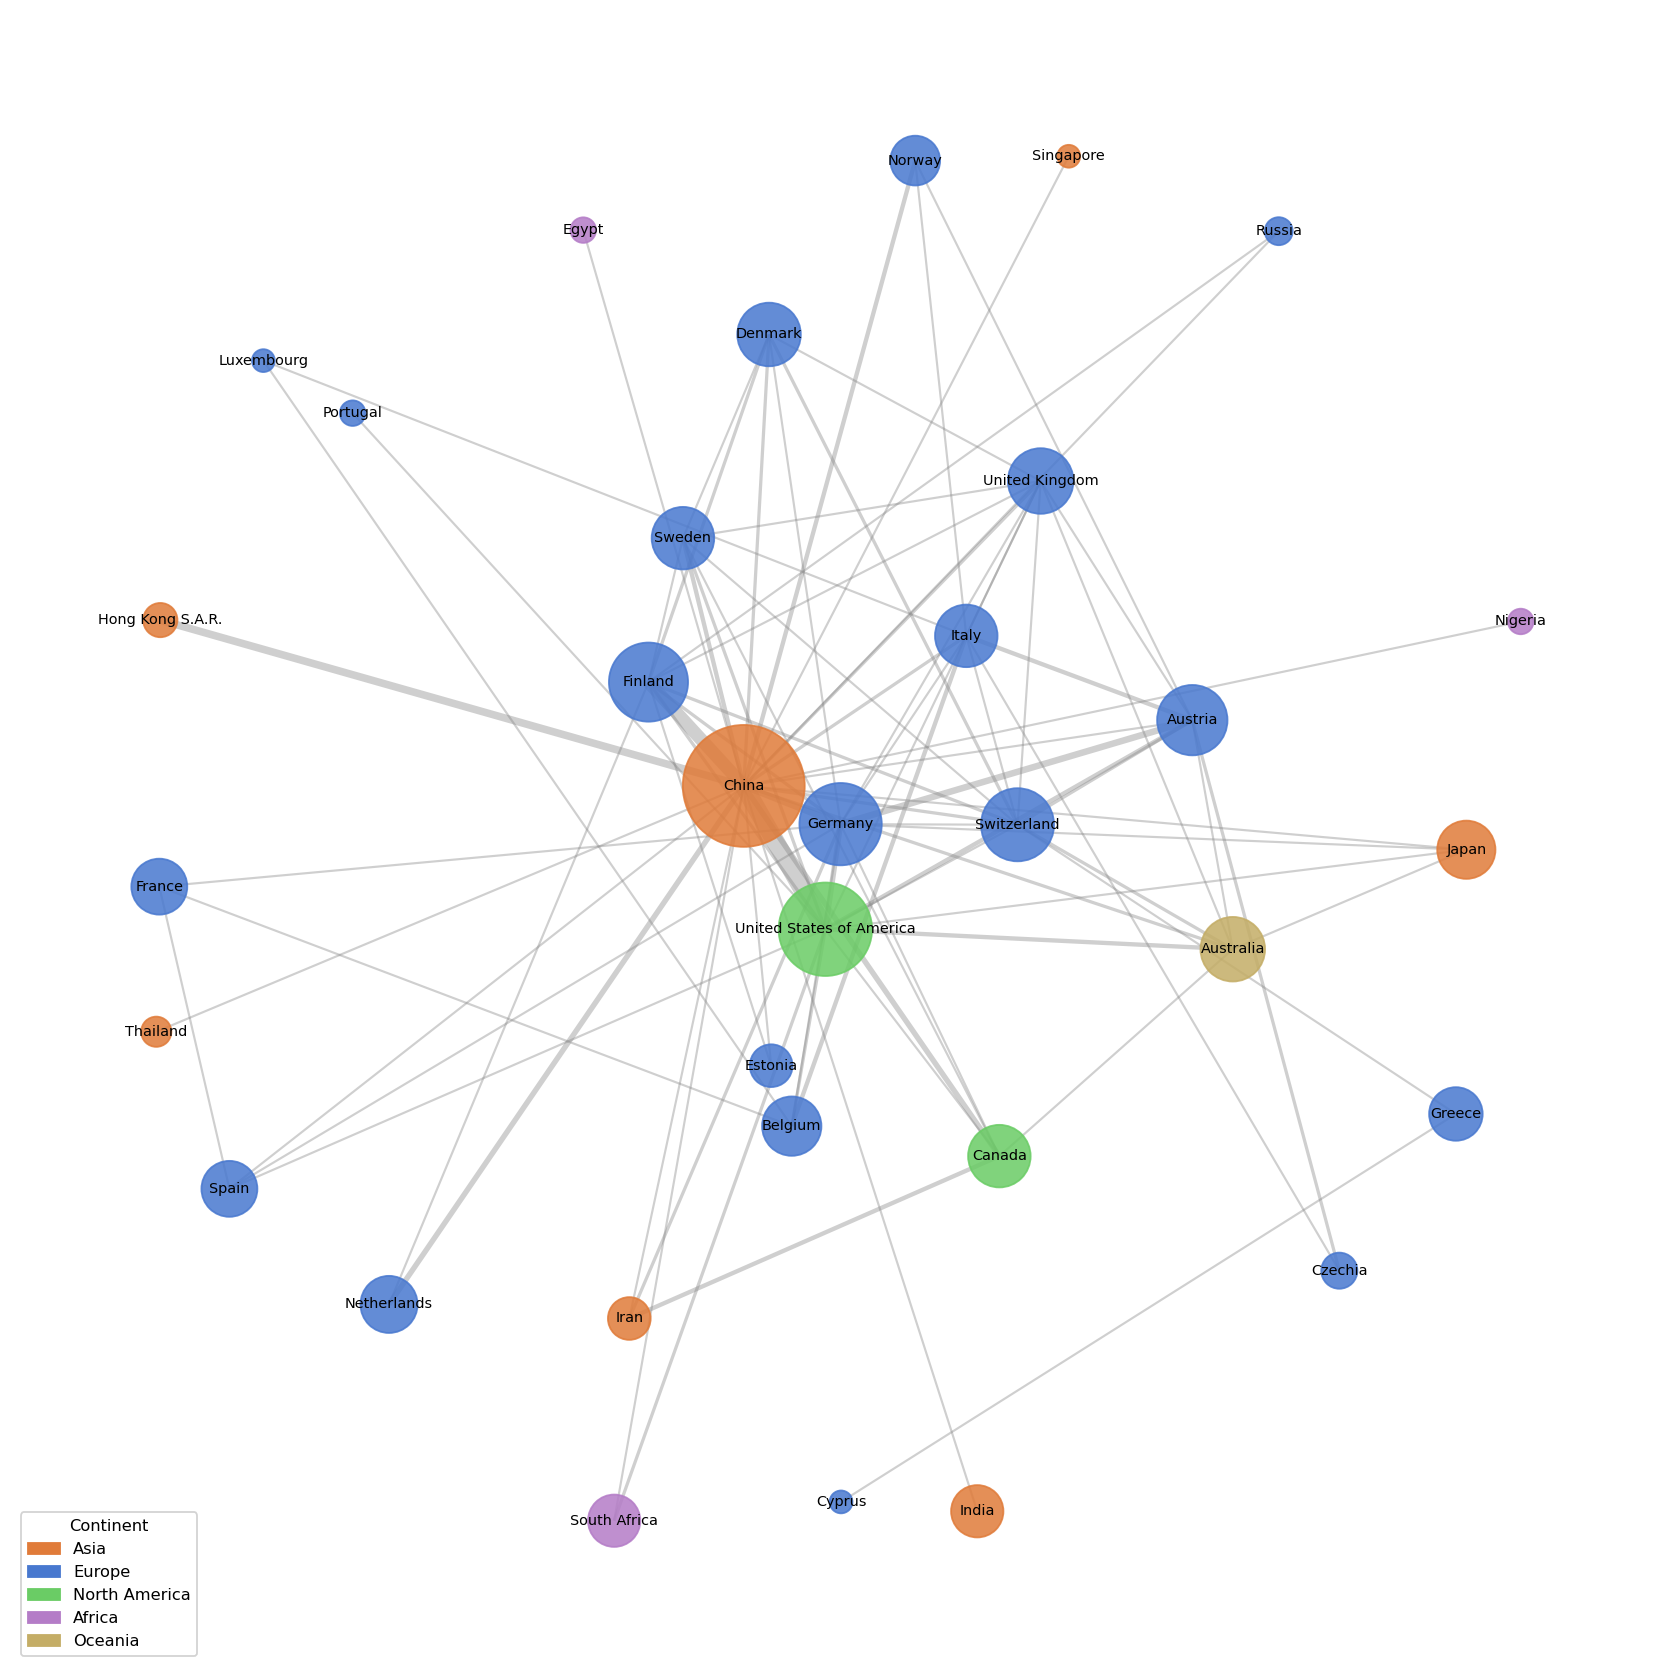

Saved -> figures/fig_A2_collab_network.png (33 countries with bilateral co-authorships >= 2)


In [11]:
CONT_COLORS = {
    'Asia': '#e07b39',
    'Europe': '#4878cf',
    'North America': '#6acc65',
    'South America': '#d65f5f',
    'Africa': '#b47cc7',
    'Oceania': '#c4ad66',
}

MIN_EDGE = 2
G_cty = nx.Graph()
for _, row in collab.iterrows():
    if row['num'] >= MIN_EDGE:
        G_cty.add_edge(row['country_1'], row['country_2'], weight=int(row['num']))

node_collab_count = defaultdict(int)
for _, row in collab.iterrows():
    node_collab_count[row['country_1']] += int(row['num'])
    node_collab_count[row['country_2']] += int(row['num'])

node_sizes = [node_collab_count.get(n, 1) * 40 for n in G_cty.nodes()]
node_colors = [CONT_COLORS.get(CONTINENT.get(n, 'Other'), '#aaaaaa') for n in G_cty.nodes()]
edge_weights = [G_cty[u][v]['weight'] for u, v in G_cty.edges()]

fig, ax = plt.subplots(figsize=(13, 13), facecolor='white')
ax.set_facecolor('white')
pos_cty = nx.spring_layout(G_cty, k=1.8, seed=42, weight='weight')

nx.draw_networkx_edges(G_cty, pos_cty, width=[w * 0.6 for w in edge_weights],
                       alpha=0.4, edge_color='#888888', ax=ax)
nx.draw_networkx_nodes(G_cty, pos_cty, ax=ax, node_size=node_sizes,
                       node_color=node_colors, alpha=0.85)
nx.draw_networkx_labels(G_cty, pos_cty, font_size=8, font_family='sans-serif', ax=ax)

handles = [
    mpatches.Patch(color=c, label=k)
    for k, c in CONT_COLORS.items()
    if any(CONTINENT.get(n) == k for n in G_cty.nodes())
]
ax.legend(handles=handles, loc='lower left', fontsize=9, framealpha=0.85,
          title='Continent', title_fontsize=9)
ax.axis('off')
fig.tight_layout()

out_fa2 = FIGURES_DIR / 'fig_A2_collab_network.png'
fig.savefig(out_fa2, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print(f"Saved -> {out_fa2} ({G_cty.number_of_nodes()} countries with bilateral co-authorships >= {MIN_EDGE})")

## 12. Figure A3 (Appendix) — Global Distribution of Author Affiliation Cities

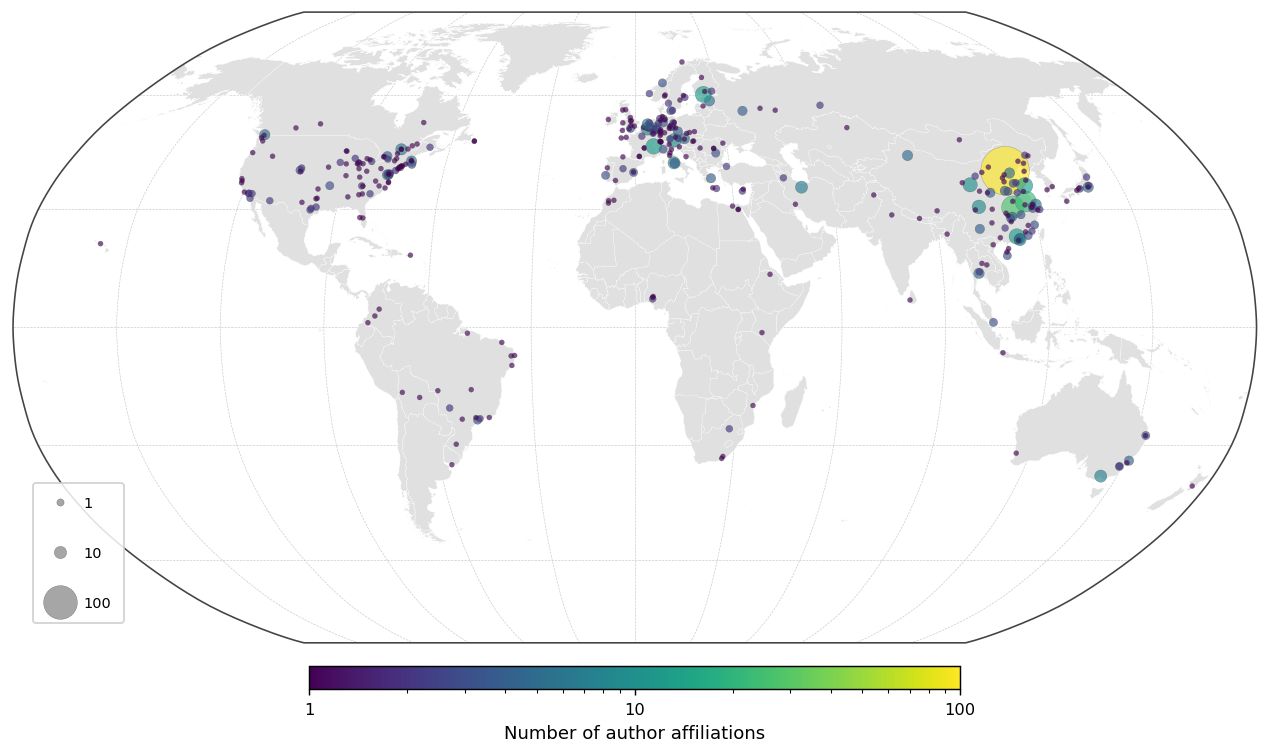

Saved -> figures/fig_A3_cities_map.png (348 geocoded cities plotted)


In [12]:
vmin_c, vmax_c = 1, 100
cmap_city = plt.get_cmap('viridis')
norm_city = mcolors.LogNorm(vmin=vmin_c, vmax=vmax_c)

proj = ccrs.Robinson()
fig = plt.figure(figsize=(12, 6), facecolor='white')
ax = fig.add_subplot(1, 1, 1, projection=proj, facecolor='white')
ax.set_global()
ax.gridlines(crs=ccrs.PlateCarree(), xlocs=range(-180, 181, 30),
             ylocs=range(-60, 61, 30), linewidth=0.35, color='#bbbbbb',
             linestyle='--', alpha=0.8)
ax.add_geometries(world.geometry, crs=ccrs.PlateCarree(),
                  facecolor='#e0e0e0', edgecolor='white', linewidth=0.15, zorder=2)

bubble_size = lambda n: np.power(n, 0.9) * 8
ax.scatter(cities_geo['lon'], cities_geo['lat'],
           s=cities_geo['num'].apply(bubble_size),
           c=np.clip(cities_geo['num'], vmin_c, vmax_c),
           cmap=cmap_city, norm=norm_city,
           alpha=0.65, linewidths=0.15, edgecolors='#333333',
           transform=ccrs.PlateCarree(), zorder=5)
ax.spines['geo'].set_linewidth(0.9)
ax.spines['geo'].set_edgecolor('#444444')

sm = plt.cm.ScalarMappable(cmap=cmap_city, norm=norm_city)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation='horizontal', shrink=0.42, pad=0.03, aspect=28)
cbar.set_label('Number of author affiliations', fontsize=10)
cbar.ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f'{int(v)}'))
cbar.ax.tick_params(labelsize=9)

legend_ms = lambda n: max(4, np.sqrt(bubble_size(min(n, 95))) * 0.85)
handles = [
    mlines.Line2D([], [], marker='o', linestyle='None', markersize=legend_ms(v),
                  color='#888888', markeredgecolor='#444444', markeredgewidth=0.2,
                  alpha=0.75, label=str(v))
    for v in [1, 10, 100]
]
ax.legend(handles=handles, loc='lower left', framealpha=0.85, fontsize=8,
          borderpad=0.9, handletextpad=0.6, labelspacing=2.5, bbox_to_anchor=(0.01, 0.02))

plt.tight_layout(pad=0.3)
out_fa3 = FIGURES_DIR / 'fig_A3_cities_map.png'
fig.savefig(out_fa3, dpi=300, bbox_inches='tight', facecolor='white')
plt.show()
plt.close(fig)
print(f"Saved -> {out_fa3} ({len(cities_geo)} geocoded cities plotted)")

## 13. Verification of All Manuscript Statistics

In [13]:
v2017 = int(metrics.loc[metrics['year'] == 2017, 'citable'].iloc[0])
v2025 = int(metrics.loc[metrics['year'] == 2025, 'citable'].iloc[0])
cagr_17_25 = ((v2025 / v2017) ** (1 / 8) - 1) * 100

total_cit = int(metrics['citable'].sum())
one_paper_cty = int((countries['num'] == 1).sum())
cty_2017 = int((countries_year['year'] == 2017).sum())
cty_2025 = int((countries_year['year'] == 2025).sum())

total_inst_occ = int(inst_totals['num'].sum())
unique_insts = len(inst_totals)
one_occ_insts = int((inst_totals['num'] == 1).sum())
top3_inst_sum = int(inst_totals.head(3)['num'].sum())

one_off_pairs = int((collab['num'] == 1).sum())
ge5_pairs = int((collab['num'] >= 5).sum())
china_pairs = int(((collab['country_1'] == 'China') | (collab['country_2'] == 'China')).sum())
china_weighted = int(collab.loc[(collab['country_1'] == 'China') | (collab['country_2'] == 'China'), 'num'].sum())

cross_cont_total = sum(r['num'] for r in cross_rows)
cont_lookup = {(r['cont_1'], r['cont_2']): int(r['num']) for _, r in cont_agg.iterrows()}
top3_cross = (
    cont_lookup.get(('Asia', 'Europe'), 0)
    + cont_lookup.get(('Europe', 'North America'), 0)
    + cont_lookup.get(('Asia', 'North America'), 0)
)

print("=" * 72)
print("MANUSCRIPT STATISTICS SUMMARY (N = 339 CITABLE ITEMS)")
print("=" * 72)
print(f"Total indexed items       : {int(metrics['total_items'].sum())} (339 citable + 15 editorials + 2 errata)")
print(f"Composition               : {int(metrics['articles'].sum())} articles ({metrics['articles'].sum()/total_cit*100:.1f}%), "
      f"{int(metrics['notes'].sum())} notes ({metrics['notes'].sum()/total_cit*100:.1f}%), "
      f"{int(metrics['reviews'].sum())} reviews ({metrics['reviews'].sum()/total_cit*100:.1f}%)")
print(f"Volume growth (2017-2025) : {v2017} -> {v2025} citable items | CAGR = {cagr_17_25:.1f}%")
print(f"Open access               : {int(metrics['open_access'].sum())}/{total_cit} (100.0%)")
print(f"Countries                 : {len(countries)} total | {one_paper_cty} with 1 paper | {cty_2017} (2017) -> {cty_2025} (2025)")
print(f"Top 5 countries           : " + ", ".join(
    f"{r['country']} ({int(r['num'])}; {r['num']/total_cit*100:.1f}%)"
    for _, r in countries.head(5).iterrows()
))
print(f"China vs next 4 combined  : {int(countries.iloc[0]['num'])} vs {int(countries.iloc[1:5]['num'].sum())}")
print(f"Institutions (normalized) : {unique_insts} unique | {total_inst_occ} occurrences | "
      f"{one_occ_insts} ({one_occ_insts/unique_insts*100:.1f}%) appear once")
print(f"Top 3 institutions        : " + ", ".join(
    f"{r['institution_norm']} ({int(r['num'])})" for _, r in inst_totals.head(3).iterrows()
) + f" -> sum={top3_inst_sum} ({top3_inst_sum/total_inst_occ*100:.1f}%)")
named_cities = int((cities['city'].str.lower() != 'unknown').sum())
print(f"Cities                    : {named_cities} named ({len(cities)} rows incl. 4 unspecified) | Top 2: " + ", ".join(
    f"{r['city']} ({int(r['num'])})" for _, r in cities.sort_values('num', ascending=False).head(2).iterrows()
))
print(f"Multi-country items       : {int(metrics['multi_country'].sum())}/{total_cit} ({overall_col:.1f}%) | "
      f"annual range {metrics['collab_rate'].min():.1f}%-{metrics['collab_rate'].max():.1f}%")
print(f"Bilateral country pairs   : {len(collab)} pairs | {one_off_pairs} ({one_off_pairs/len(collab)*100:.1f}%) single-paper | "
      f"{ge5_pairs} pairs >= 5 papers")
print(f"Top 3 country pairs       : " + ", ".join(
    f"{r['country_1']}--{r['country_2']} ({int(r['num'])})" for _, r in collab.head(3).iterrows()
))
print(f"China in country pairs    : {china_pairs}/{len(collab)} ({china_pairs/len(collab)*100:.1f}%) distinct | "
      f"{china_weighted}/{int(collab['num'].sum())} ({china_weighted/collab['num'].sum()*100:.1f}%) weighted")
print(f"Intra-continental loops   : Europe={self_loops.get('Europe', 0)}, Asia={self_loops.get('Asia', 0)}")
print(f"Top 3 cross-continental   : Asia--Europe ({cont_lookup.get(('Asia', 'Europe'), 0)}), "
      f"Europe--North America ({cont_lookup.get(('Europe', 'North America'), 0)}), "
      f"Asia--North America ({cont_lookup.get(('Asia', 'North America'), 0)}) "
      f"= {top3_cross}/{cross_cont_total} ({top3_cross/cross_cont_total*100:.1f}%)")
print("=" * 72)

MANUSCRIPT STATISTICS SUMMARY (N = 339 CITABLE ITEMS)
Total indexed items       : 356 (339 citable + 15 editorials + 2 errata)
Composition               : 276 articles (81.4%), 51 notes (15.0%), 12 reviews (3.5%)
Volume growth (2017-2025) : 11 -> 58 citable items | CAGR = 23.1%
Open access               : 339/339 (100.0%)
Countries                 : 60 total | 24 with 1 paper | 9 (2017) -> 34 (2025)
Top 5 countries           : China (196; 57.8%), United States of America (53; 15.6%), Germany (26; 7.7%), Canada (21; 6.2%), Australia (17; 5.0%)
China vs next 4 combined  : 196 vs 117
Institutions (normalized) : 581 unique | 1114 occurrences | 446 (76.8%) appear once
Top 3 institutions        : Chinese Academy of Sciences (150), University of Chinese Academy of Sciences (58), Wuhan University (19) -> sum=227 (20.4%)
Cities                    : 348 named (352 rows incl. 4 unspecified) | Top 2: Beijing (149), Wuhan (27)
Multi-country items       : 114/339 (33.6%) | annual range 22.2%-50.0%
B